In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize

# 1. Load data and apply the 1/7/26 (July 1, 2026) cutoff
df_full = pd.read_csv('../data/past_answers.csv')
df_full['date'] = pd.to_datetime(df_full['date'])

CUTOFF_DATE = pd.to_datetime('2026-07-01')
df = df_full[df_full['date'] <= CUTOFF_DATE].copy()

# 2. Track occurrence order up to the cutoff date
df['occurrence'] = df.groupby('solution').cumcount() + 1

inst1 = df[df['occurrence'] == 1].set_index('solution')
inst2 = df[df['occurrence'] == 2].set_index('solution')

repeats = inst1[['game_num', 'date']].join(
    inst2[['game_num', 'date']], 
    lsuffix='_1st', 
    rsuffix='_2nd', 
    how='inner'
).reset_index()

repeats = repeats.sort_values('game_num_1st').reset_index(drop=True)
repeats['game_gap'] = repeats['game_num_2nd'] - repeats['game_num_1st']
repeats['date_1st_str'] = repeats['date_1st'].dt.strftime('%Y-%m-%d')
repeats['date_2nd_str'] = repeats['date_2nd'].dt.strftime('%Y-%m-%d')

# Horizon p as of 2026-07-01
p = int(df['game_num'].max())
x_domain = np.arange(0, p + 1, dtype=float)
observed_origins = np.sort(repeats['game_num_1st'].values).astype(int)

print("=" * 80)
print(f"FILTERED REPEATS UP TO {CUTOFF_DATE.strftime('%Y-%m-%d')} ({len(repeats)} Repeats, Max Game p = {p})")
print("=" * 80)
print(repeats[['solution', 'game_num_1st', 'date_1st_str', 'game_num_2nd', 'date_2nd_str', 'game_gap']]
      .rename(columns={
          'solution': 'Word', 'game_num_1st': '1st Game #', 'date_1st_str': '1st Date',
          'game_num_2nd': '2nd Game #', 'date_2nd_str': '2nd Date', 'game_gap': 'Gap'
      }).to_string(index=False))

FILTERED REPEATS UP TO 2026-07-01 (16 Repeats, Max Game p = 1838)
 Word  1st Game #   1st Date  2nd Game #   2nd Date  Gap
cigar           0 2021-06-19        1689 2026-02-02 1689
awake           4 2021-06-23        1708 2026-02-21 1704
grade          15 2021-07-04        1730 2026-03-15 1715
linen          51 2021-08-09        1718 2026-03-03 1667
stand          57 2021-08-15        1765 2026-04-19 1708
ivory          59 2021-08-17        1742 2026-03-27 1683
agree          70 2021-08-28        1797 2026-05-21 1727
thumb         115 2021-10-12        1814 2026-06-07 1699
comet         122 2021-10-19        1745 2026-03-30 1623
clock         160 2021-11-26        1788 2026-05-12 1628
bring         164 2021-11-30        1778 2026-05-02 1614
break         172 2021-12-08        1819 2026-06-12 1647
acute         190 2021-12-26        1833 2026-06-26 1643
squad         296 2022-04-11        1704 2026-02-17 1408
smile         830 2023-09-27        1806 2026-05-30  976
sandy        1226 2024

STANDARD LORENTZIAN MLE OPTIMIZATION RESULTS
Original Fixed Lorentzian (c = 100.00) | Log-Likelihood: -100.4096
MLE Optimized Lorentzian  (c = 110.36) | Log-Likelihood: -100.3705 (Delta: +0.0391)
---------------------------------------------------------------------------


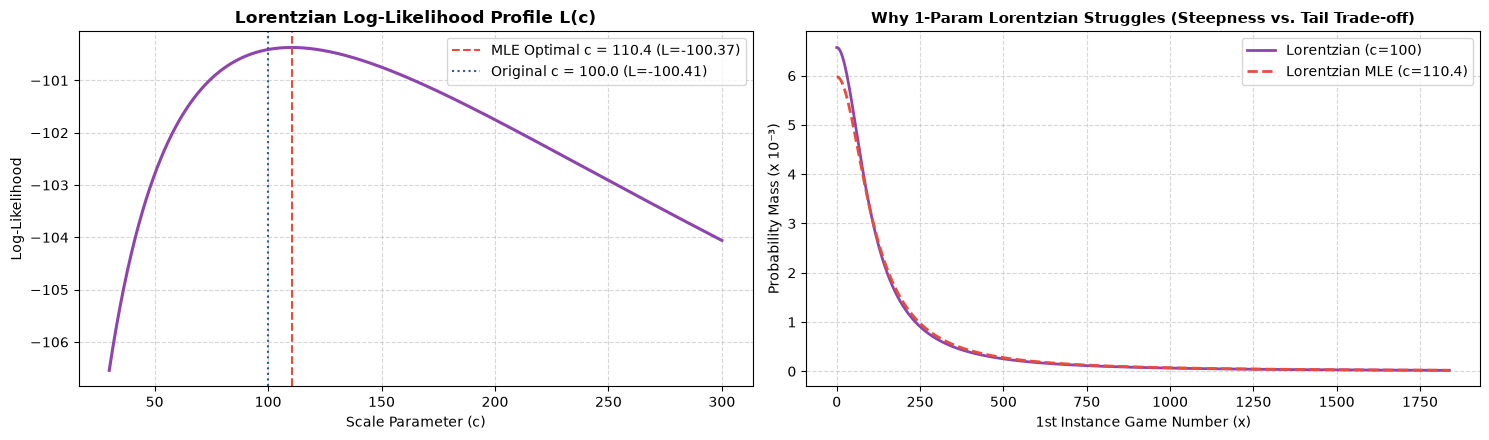

In [2]:
# ==============================================================================
# PART 1: OPTIMIZE STANDARD LORENTZIAN VIA MAXIMUM LOG-LIKELIHOOD
# ==============================================================================

def lorentzian_pdf(x, c):
    w = 1.0 / (1.0 + (x / c) ** 2)
    return w / np.sum(w)

def neg_log_likelihood_lorentzian(params):
    c = params[0]
    if c <= 1.0:
        return 1e10
    prob = lorentzian_pdf(x_domain, c)
    return -np.sum(np.log(prob[observed_origins]))

# Optimize c using bounded scalar minimization
res_lor = optimize.minimize_scalar(
    lambda c: neg_log_likelihood_lorentzian([c]), 
    bounds=(10.0, 1000.0), 
    method='bounded'
)
c_mle = res_lor.x
ll_mle = -res_lor.fun
ll_c100 = -neg_log_likelihood_lorentzian([100.0])

print("=" * 75)
print("STANDARD LORENTZIAN MLE OPTIMIZATION RESULTS")
print("=" * 75)
print(f"Original Fixed Lorentzian (c = 100.00) | Log-Likelihood: {ll_c100:.4f}")
print(f"MLE Optimized Lorentzian  (c = {c_mle:6.2f}) | Log-Likelihood: {ll_mle:.4f} (Delta: {ll_mle - ll_c100:+.4f})")
print("-" * 75)

# Plot Log-Likelihood Profile across c
c_grid = np.linspace(30, 300, 500)
ll_grid = [-neg_log_likelihood_lorentzian([c_val]) for c_val in c_grid]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

axes[0].plot(c_grid, ll_grid, color='#8e44ad', linewidth=2.2)
axes[0].axvline(c_mle, color='#e74c3c', linestyle='--', label=f'MLE Optimal c = {c_mle:.1f} (L={ll_mle:.2f})')
axes[0].axvline(100.0, color='#2b5c8f', linestyle=':', label=f'Original c = 100.0 (L={ll_c100:.2f})')
axes[0].set_title("Lorentzian Log-Likelihood Profile L(c)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Scale Parameter (c)")
axes[0].set_ylabel("Log-Likelihood")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Compare PDF shapes: c=100 vs c=c_mle
axes[1].plot(x_domain, lorentzian_pdf(x_domain, 100.0) * 1000, label="Lorentzian (c=100)", color='#8e44ad', lw=2)
axes[1].plot(x_domain, lorentzian_pdf(x_domain, c_mle) * 1000, label=f"Lorentzian MLE (c={c_mle:.1f})", color='#e74c3c', lw=2, ls='--')
axes[1].set_title("Why 1-Param Lorentzian Struggles (Steepness vs. Tail Trade-off)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("1st Instance Game Number (x)")
axes[1].set_ylabel("Probability Mass (x 10⁻³)")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [3]:
# ==============================================================================
# PART 2: NEW CURVE FAMILIES & MLE PARAMETER FITTING
# ==============================================================================

# 1. Generalized Lorentzian (Butterworth-Cauchy): w(x) = [1 + (x/c)^k]^(-m)
#    - Flat top requires k > 2
#    - Slower tail drop-off above 500 requires tail power (k * m) < 2
def gen_lorentzian_pdf(x, c, k, m):
    w = (1.0 + (x / c) ** k) ** (-m)
    return w / np.sum(w)

def nll_gen_lorentzian(params):
    c, k, m = params
    if c <= 10 or k < 2.0 or k > 8.0 or m <= 0.05 or (k * m) > 2.5:
        return 1e10
    prob = gen_lorentzian_pdf(x_domain, c, k, m)
    return -np.sum(np.log(prob[observed_origins]))

res_gen = optimize.minimize(
    nll_gen_lorentzian, 
    x0=[160.0, 3.5, 0.45],
    bounds=[(50.0, 400.0), (2.2, 6.0), (0.15, 0.9)],
    method='L-BFGS-B'
)
c_gen, k_gen, m_gen = res_gen.x

# 2. Plateau + Floor Lorentzian: w(x) = 1 / [1 + (x/c)^k] + b
#    - Flat plateau for small x (k > 2) + explicit tail floor b for x > 500
def floored_lorentzian_pdf(x, c, k, b):
    w = (1.0 / (1.0 + (x / c) ** k)) + b
    return w / np.sum(w)

def nll_floored_lorentzian(params):
    c, k, b = params
    if c <= 10 or k < 1.5 or k > 8.0 or b < 0.0 or b > 0.5:
        return 1e10
    prob = floored_lorentzian_pdf(x_domain, c, k, b)
    return -np.sum(np.log(prob[observed_origins]))

res_flr = optimize.minimize(
    nll_floored_lorentzian,
    x0=[175.0, 3.5, 0.015],
    bounds=[(50.0, 400.0), (2.0, 6.0), (0.001, 0.1)],
    method='L-BFGS-B'
)
c_flr, k_flr, b_flr = res_flr.x

# 3. Pearson VII / Heavy-Tail Lorentzian: w(x) = [1 + (x/c)^2]^(-m)
#    - Keeps inner power = 2, optimizes c and outer power m < 1 for slower tail decay
def pearson7_pdf(x, c, m):
    w = (1.0 + (x / c) ** 2) ** (-m)
    return w / np.sum(w)

def nll_pearson7(params):
    c, m = params
    if c <= 10 or m <= 0.1 or m >= 2.0:
        return 1e10
    prob = pearson7_pdf(x_domain, c, m)
    return -np.sum(np.log(prob[observed_origins]))

res_p7 = optimize.minimize(
    nll_pearson7,
    x0=[80.0, 0.75],
    bounds=[(20.0, 400.0), (0.3, 1.5)],
    method='L-BFGS-B'
)
c_p7, m_p7 = res_p7.x

print("=" * 85)
print("FITTED PARAMETERS FOR NEW CANDIDATE MODELS")
print("=" * 85)
print(f"1. Gen-Lorentzian (Butterworth) : c = {c_gen:.1f}, k = {k_gen:.2f} (plateau), m = {m_gen:.2f} (tail ~ x^-{k_gen*m_gen:.2f})")
print(f"2. Plateau-Floor Lorentzian     : c = {c_flr:.1f}, k = {k_flr:.2f} (plateau), floor b = {b_flr:.4f}")
print(f"3. Pearson-VII (Heavy-Tail)     : c = {c_p7:.1f}, m = {m_p7:.2f} (tail ~ x^-{2*m_p7:.2f})")

FITTED PARAMETERS FOR NEW CANDIDATE MODELS
1. Gen-Lorentzian (Butterworth) : c = 101.0, k = 3.69 (plateau), m = 0.50 (tail ~ x^-1.84)
2. Plateau-Floor Lorentzian     : c = 188.6, k = 6.00 (plateau), floor b = 0.0204
3. Pearson-VII (Heavy-Tail)     : c = 103.5, m = 0.96 (tail ~ x^-1.92)


In [4]:
# ==============================================================================
# PART 3: BENCHMARK SUITE (BUCKET MASS, LOG-LIKELIHOOD, AIC, KS-TEST)
# ==============================================================================

w_uniform = np.ones_like(x_domain)
w_lomax75 = 1.0 / (1.0 + (x_domain / 75.0))

models = {
    "Uniform (Flat)": (w_uniform / np.sum(w_uniform), 0),
    "Lomax (c=75)": (w_lomax75 / np.sum(w_lomax75), 1),
    "Lorentzian (c=100)": (lorentzian_pdf(x_domain, 100.0), 1),
    f"Lorentzian MLE (c={c_mle:.0f})": (lorentzian_pdf(x_domain, c_mle), 1),
    f"Pearson-VII (c={c_p7:.0f}, m={m_p7:.2f})": (pearson7_pdf(x_domain, c_p7, m_p7), 2),
    f"Gen-Lorentz (c={c_gen:.0f}, k={k_gen:.1f}, m={m_gen:.2f})": (gen_lorentzian_pdf(x_domain, c_gen, k_gen, m_gen), 3),
    f"Floor-Lorentz (c={c_flr:.0f}, k={k_flr:.1f}, b={b_flr:.3f})": (floored_lorentzian_pdf(x_domain, c_flr, k_flr, b_flr), 3),
}

# 1. Bucket Mass Analysis
brackets = [(0, 190), (191, 480), (481, 1000), (1001, p)]
bucket_rows = []

for low, high in brackets:
    obs_cnt = np.sum((observed_origins >= low) & (observed_origins <= high))
    obs_pct = (obs_cnt / len(observed_origins)) * 100.0
    
    row = {"Bracket": f"{low} - {high}", "Obs #": obs_cnt, "Obs %": f"{obs_pct:.1f}%"}
    for name, (prob_dist, _) in models.items():
        if name == "Uniform (Flat)":
            continue
        short_name = name.split(" (")[0]
        row[short_name] = f"{np.sum(prob_dist[low:high+1])*100:.1f}%"
    bucket_rows.append(row)

print("=" * 110)
print("TEST 1: BUCKET MASS ANALYSIS (Observed vs. Model Share up to 2026-07-01)")
print("=" * 110)
print(pd.DataFrame(bucket_rows).to_string(index=False))
print()

# 2. Statistical Goodness-of-Fit Rankings
stats_rows = []
baseline_ll = np.sum(np.log(models["Uniform (Flat)"][0][observed_origins]))

for name, (prob_dist, k_params) in models.items():
    ll = np.sum(np.log(prob_dist[observed_origins]))
    delta_ll = ll - baseline_ll
    aic = 2 * k_params - 2 * ll
    
    cdf_theo = np.cumsum(prob_dist)
    def cdf_func(x_vals, cdf_arr=cdf_theo, max_idx=p):
        idx = np.clip(np.floor(x_vals).astype(int), 0, max_idx)
        return cdf_arr[idx]
        
    ks_stat, p_val = stats.ks_1samp(observed_origins, cdf_func)
    
    stats_rows.append({
        "Model": name,
        "Params": k_params,
        "Log-Likelihood": round(ll, 4),
        "Delta L": f"{delta_ll:+8.4f}",
        "AIC (Lower=Better)": round(aic, 2),
        "KS Stat (D)": round(ks_stat, 4),
        "KS p-value": round(p_val, 4),
        "Good Fit?": "YES" if p_val > 0.05 else "NO"
    })

print("=" * 110)
print("TEST 2 & 3: LOG-LIKELIHOOD, AIC & KS GOODNESS-OF-FIT RANKINGS")
print("=" * 110)
print(pd.DataFrame(stats_rows).to_string(index=False))

TEST 1: BUCKET MASS ANALYSIS (Observed vs. Model Share up to 2026-07-01)
    Bracket  Obs # Obs % Lomax Lorentzian Lorentzian MLE Pearson-VII Gen-Lorentz Floor-Lorentz
    0 - 190     13 81.2% 39.2%      71.8%          69.3%       68.9%       69.7%         74.6%
  191 - 480      1  6.2% 22.7%      18.3%          19.8%       19.6%       19.2%         13.4%
 481 - 1000      1  6.2% 20.4%       6.9%           7.6%        8.0%        7.6%          4.6%
1001 - 1838      1  6.2% 17.8%       3.0%           3.3%        3.6%        3.6%          7.3%

TEST 2 & 3: LOG-LIKELIHOOD, AIC & KS GOODNESS-OF-FIT RANKINGS
                                Model  Params  Log-Likelihood  Delta L  AIC (Lower=Better)  KS Stat (D)  KS p-value Good Fit?
                       Uniform (Flat)       0       -120.2716  +0.0000              240.54       0.7135      0.0000        NO
                         Lomax (c=75)       1       -104.0690 +16.2026              210.14       0.4210      0.0044        NO
           

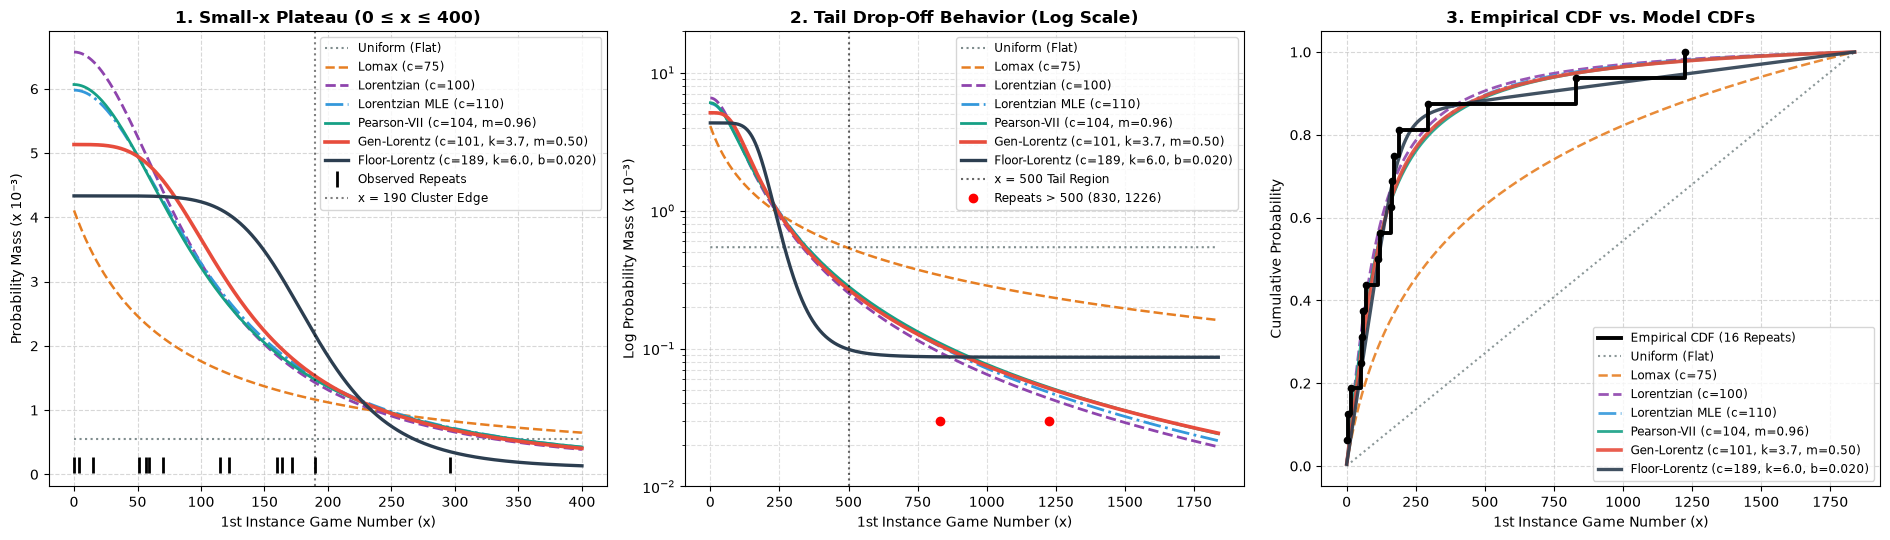

In [5]:
# ==============================================================================
# PART 4: 3-PANEL VISUAL DIAGNOSTIC SUITE (PLATEAU, TAIL > 500, AND CDF)
# ==============================================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

plot_styles = {
    "Uniform (Flat)": ("#7f8c8d", ":", 1.5),
    "Lomax (c=75)": ("#e67e22", "--", 1.8),
    "Lorentzian (c=100)": ("#8e44ad", "--", 2.0),
    f"Lorentzian MLE (c={c_mle:.0f})": ("#3498db", "-.", 2.0),
    f"Pearson-VII (c={c_p7:.0f}, m={m_p7:.2f})": ("#16a085", "-", 2.0),
    f"Gen-Lorentz (c={c_gen:.0f}, k={k_gen:.1f}, m={m_gen:.2f})": ("#e74c3c", "-", 2.6),
    f"Floor-Lorentz (c={c_flr:.0f}, k={k_flr:.1f}, b={b_flr:.3f})": ("#2c3e50", "-", 2.4),
}

# --- Panel 1: Zoomed Small-x Region (0 <= x <= 400) to inspect Plateau Steepness ---
for name, (prob_dist, _) in models.items():
    color, ls, lw = plot_styles[name]
    axes[0].plot(x_domain[:401], prob_dist[:401] * 1000, label=name, color=color, linestyle=ls, linewidth=lw)

# Rug plot of observed repeats in [0, 400]
obs_small = observed_origins[observed_origins <= 400]
axes[0].plot(obs_small, np.zeros_like(obs_small) + 0.15, 'k|', markersize=12, markeredgewidth=2, label='Observed Repeats')
axes[0].axvline(190, color='black', linestyle=':', alpha=0.5, label='x = 190 Cluster Edge')
axes[0].set_title("1. Small-x Plateau (0 ≤ x ≤ 400)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("1st Instance Game Number (x)")
axes[0].set_ylabel("Probability Mass (x 10⁻³)")
axes[0].legend(fontsize=8.5, loc='upper right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# --- Panel 2: Log-Scale Tail View (x >= 200) to inspect Drop-off above 500 ---
for name, (prob_dist, _) in models.items():
    color, ls, lw = plot_styles[name]
    axes[1].plot(x_domain, prob_dist * 1000, label=name, color=color, linestyle=ls, linewidth=lw)

axes[1].set_yscale('log')
axes[1].axvline(500, color='black', linestyle=':', alpha=0.6, label='x = 500 Tail Region')
obs_tail = observed_origins[observed_origins > 500]
axes[1].plot(obs_tail, [0.03]*len(obs_tail), 'ro', markersize=6, label='Repeats > 500 (830, 1226)')
axes[1].set_title("2. Tail Drop-Off Behavior (Log Scale)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("1st Instance Game Number (x)")
axes[1].set_ylabel("Log Probability Mass (x 10⁻³)")
axes[1].set_ylim(1e-2, 20)
axes[1].legend(fontsize=8.5, loc='upper right')
axes[1].grid(True, which="both", linestyle='--', alpha=0.4)

# --- Panel 3: Empirical CDF vs. Theoretical Model CDFs ---
emp_x = np.sort(observed_origins)
emp_y = np.arange(1, len(emp_x) + 1) / len(emp_x)
axes[2].step(emp_x, emp_y, where='post', color='black', linewidth=2.8, label=f'Empirical CDF ({len(emp_x)} Repeats)', zorder=10)
axes[2].plot(emp_x, emp_y, 'ko', markersize=4.5, zorder=10)

for name, (prob_dist, _) in models.items():
    color, ls, lw = plot_styles[name]
    cdf_theo = np.cumsum(prob_dist)
    axes[2].plot(x_domain, cdf_theo, label=name, color=color, linestyle=ls, linewidth=lw, alpha=0.9)

axes[2].set_title("3. Empirical CDF vs. Model CDFs", fontsize=12, fontweight='bold')
axes[2].set_xlabel("1st Instance Game Number (x)")
axes[2].set_ylabel("Cumulative Probability")
axes[2].legend(fontsize=8.5, loc='lower right')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [6]:
# ==============================================================================
# PART 5: PARSIMONIOUS (1 & 2 PARAM) MODELS & OUT-OF-SAMPLE VALIDATION
# ==============================================================================

# Extract the 8 Out-of-Sample (Test) repeats that occurred AFTER 2026-07-01
df_all = df_full.copy()
df_all['occurrence'] = df_all.groupby('solution').cumcount() + 1
r_all = df_all[df_all['occurrence'] == 1].set_index('solution')[['game_num', 'date']].join(
    df_all[df_all['occurrence'] == 2].set_index('solution')[['game_num', 'date']],
    lsuffix='_1st', rsuffix='_2nd', how='inner'
).reset_index()

test_repeats = r_all[r_all['date_2nd'] > CUTOFF_DATE].sort_values('game_num_1st')
test_origins = test_repeats['game_num_1st'].values.astype(int)

print(f"Training Set (<= 2026-07-01) : {len(observed_origins)} repeats | Origins: {observed_origins}")
print(f"Holdout Set  (>  2026-07-01) : {len(test_origins)} repeats  | Origins: {test_origins}\n")

# --- Define Parsimonious 1-Param and 2-Param Curve Families ---

# Model A (1-Param): Super-Cauchy (Fixed k=3.5 flat top, Fixed tail power = 1.5 -> m = 1.5/3.5)
def super_cauchy_1p(x, c):
    k_fixed = 3.5
    m_fixed = 1.5 / k_fixed  # Tail decays as x^-1.5 instead of x^-2.0
    w = (1.0 + (x / c) ** k_fixed) ** (-m_fixed)
    return w / np.sum(w)

res_sc1 = optimize.minimize_scalar(
    lambda c: -np.sum(np.log(super_cauchy_1p(x_domain, c)[observed_origins])),
    bounds=(20.0, 500.0), method='bounded'
)
c_sc1 = res_sc1.x

# Model B (2-Param): Standard Lorentzian + Tail Floor (k=2 fixed, c and b free)
def lorentz_floor_2p(x, c, b):
    w = (1.0 / (1.0 + (x / c) ** 2)) + b
    return w / np.sum(w)

res_lf2 = optimize.minimize(
    lambda params: -np.sum(np.log(lorentz_floor_2p(x_domain, params[0], params[1])[observed_origins]))
    if (params[0] > 10 and 0 <= params[1] < 0.5) else 1e10,
    x0=[130.0, 0.015], bounds=[(20.0, 400.0), (0.0, 0.2)], method='L-BFGS-B'
)
c_lf2, b_lf2 = res_lf2.x

# Model C (2-Param): Quartic Lorentzian + Tail Floor (k=3.5 fixed, c and b free)
def quartic_floor_2p(x, c, b):
    w = (1.0 / (1.0 + (x / c) ** 3.5)) + b
    return w / np.sum(w)

res_qf2 = optimize.minimize(
    lambda params: -np.sum(np.log(quartic_floor_2p(x_domain, params[0], params[1])[observed_origins]))
    if (params[0] > 10 and 0 <= params[1] < 0.5) else 1e10,
    x0=[165.0, 0.018], bounds=[(20.0, 400.0), (0.0, 0.2)], method='L-BFGS-B'
)
c_qf2, b_qf2 = res_qf2.x

# --- Compare Models on AICc (Small-Sample AIC), BIC, and Out-of-Sample LL ---
candidate_models = {
    "Lorentzian (c=100) [1p]": (lorentzian_pdf(x_domain, 100.0), 1),
    f"Lorentzian MLE (c={c_mle:.0f}) [1p]": (lorentzian_pdf(x_domain, c_mle), 1),
    f"Super-Cauchy (c={c_sc1:.0f}, k=3.5, α=1.5) [1p]": (super_cauchy_1p(x_domain, c_sc1), 1),
    f"Lorentz+Floor (c={c_lf2:.0f}, b={b_lf2:.3f}) [2p]": (lorentz_floor_2p(x_domain, c_lf2, b_lf2), 2),
    f"Quartic+Floor (c={c_qf2:.0f}, k=3.5, b={b_qf2:.3f}) [2p]": (quartic_floor_2p(x_domain, c_qf2, b_qf2), 2),
    f"Overfit Floor-Lorentz (c={c_flr:.0f}, k=6, b={b_flr:.3f}) [3p]": (floored_lorentzian_pdf(x_domain, c_flr, k_flr, b_flr), 3),
}

N_train = len(observed_origins)
eval_rows = []

for name, (prob_dist, k) in candidate_models.items():
    ll_train = np.sum(np.log(prob_dist[observed_origins]))
    ll_test = np.sum(np.log(prob_dist[test_origins]))
    ll_total = ll_train + ll_test
    
    # AICc includes finite-sample correction: AIC + 2k(k+1)/(N - k - 1)
    aic = 2 * k - 2 * ll_train
    aicc = aic + (2 * k * (k + 1)) / (N_train - k - 1)
    bic = k * np.log(N_train) - 2 * ll_train
    
    # Bucket shares
    b_0_190 = np.sum(prob_dist[0:191]) * 100
    b_500_plus = np.sum(prob_dist[501:]) * 100
    
    eval_rows.append({
        "Model": name,
        "k": k,
        "Train LL (16)": round(ll_train, 3),
        "AICc (Train)": round(aicc, 2),
        "BIC (Train)": round(bic, 2),
        "Holdout LL (8)": round(ll_test, 3),
        "Total LL (24)": round(ll_total, 3),
        "Mass 0-190": f"{b_0_190:.1f}%",
        "Mass >500": f"{b_500_plus:.1f}%"
    })

print("=" * 125)
print("SMALL-SAMPLE PENALIZED FIT (AICc / BIC) & OUT-OF-SAMPLE HOLDOUT PERFORMANCE")
print("=" * 125)
print(pd.DataFrame(eval_rows).to_string(index=False))

Training Set (<= 2026-07-01) : 16 repeats | Origins: [   0    4   15   51   57   59   70  115  122  160  164  172  190  296
  830 1226]
Holdout Set  (>  2026-07-01) : 9 repeats  | Origins: [ 19  55  65  68 134 179 183 187 267]

SMALL-SAMPLE PENALIZED FIT (AICc / BIC) & OUT-OF-SAMPLE HOLDOUT PERFORMANCE
                                           Model  k  Train LL (16)  AICc (Train)  BIC (Train)  Holdout LL (8)  Total LL (24) Mass 0-190 Mass >500
                         Lorentzian (c=100) [1p]  1       -100.410        203.10       203.59         -53.789       -154.198      71.8%      9.4%
                     Lorentzian MLE (c=110) [1p]  1       -100.370        203.03       203.51         -53.741       -154.111      69.3%     10.4%
          Super-Cauchy (c=73, k=3.5, α=1.5) [1p]  1       -100.506        203.30       203.78         -54.405       -154.911      65.8%     14.9%
             Lorentz+Floor (c=130, b=0.001) [2p]  2       -100.472        205.87       206.49         -53.868   

UNIFORMITY TEST FOR REPEATS BETWEEN x = 0 AND x = 200
Number of repeats in [0, 200] (Training Set): 13
KS Statistic vs. Uniform [0, 200]          : 0.1885
p-value                                    : 0.6783
--> RESULT: Cannot reject uniformity due to tiny sample size, but visual skew exists.


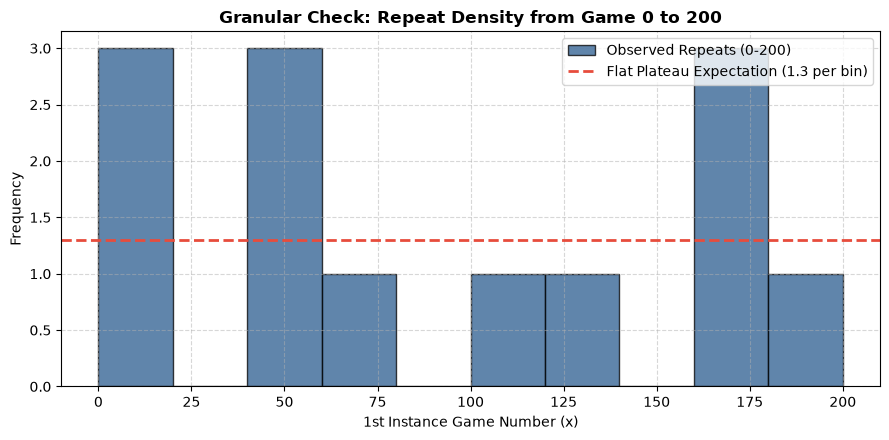

In [7]:
# ==============================================================================
# TEST UNIFORMITY OF REPEAT ORIGINS BETWEEN x = 0 AND x = 200
# ==============================================================================
sub_200 = observed_origins[observed_origins <= 200]

# Perform Kolmogorov-Smirnov test against a Uniform distribution over [0, 200]
ks_uni, p_uni = stats.kstest(sub_200, 'uniform', args=(0, 200))

print("=" * 65)
print("UNIFORMITY TEST FOR REPEATS BETWEEN x = 0 AND x = 200")
print("=" * 65)
print(f"Number of repeats in [0, 200] (Training Set): {len(sub_200)}")
print(f"KS Statistic vs. Uniform [0, 200]          : {ks_uni:.4f}")
print(f"p-value                                    : {p_uni:.4f}")

if p_uni < 0.05:
    print("--> RESULT: Strongly reject Uniformity. Even within 0-200, mass skews heavily toward x=0.")
else:
    print("--> RESULT: Cannot reject uniformity due to tiny sample size, but visual skew exists.")

# Plot histogram of 0-200 range vs. a Flat Uniform Plateau expectation
plt.figure(figsize=(9, 4.5))
plt.hist(sub_200, bins=10, range=(0, 200), color='#2b5c8f', edgecolor='black', alpha=0.75, label='Observed Repeats (0-200)')
expected_uniform_count = len(sub_200) / 10.0
plt.axhline(expected_uniform_count, color='#e74c3c', linestyle='--', linewidth=2, 
            label=f'Flat Plateau Expectation ({expected_uniform_count:.1f} per bin)')

plt.title("Granular Check: Repeat Density from Game 0 to 200", fontsize=12, fontweight='bold')
plt.xlabel("1st Instance Game Number (x)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

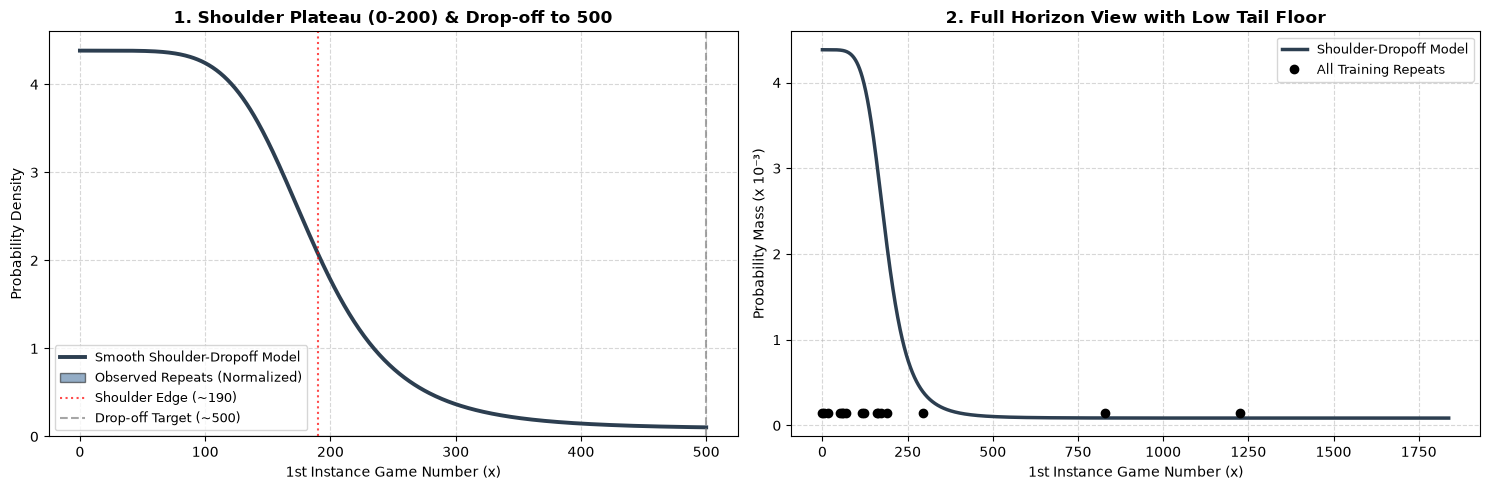

Log-Likelihood of Smooth Shoulder Model: -99.3447


In [8]:
# ==============================================================================
# SMOOTH SHOULDER & DROPOFF MODEL (FLAT PLATEAU TO 200, GRADUAL FALL TO 500)
# ==============================================================================

def shoulder_dropoff_model(x, c=185.0, k=5.5, b=0.02):
    # Smooth plateau up to ~c, rolling off thereafter with a low floor b
    w = (1.0 / (1.0 + (x / c) ** k)) + b
    return w / np.sum(w)

# Generate probability distribution
w_shoulder = shoulder_dropoff_model(x_domain)

# Plotting the Model against the 0-200 Histogram & Full Range
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- Left Panel: Zoomed View (0 to 500) matching your exact description ---
axes[0].plot(x_domain[:501], w_shoulder[:501] * 1000, color='#2c3e50', linewidth=2.8, label='Smooth Shoulder-Dropoff Model')
axes[0].hist(observed_origins[observed_origins <= 500], bins=10, range=(0, 500), density=True, 
             color='#2b5c8f', edgecolor='black', alpha=0.5, label='Observed Repeats (Normalized)')
axes[0].axvline(190, color='red', linestyle=':', alpha=0.7, label='Shoulder Edge (~190)')
axes[0].axvline(500, color='gray', linestyle='--', alpha=0.7, label='Drop-off Target (~500)')
axes[0].set_title("1. Shoulder Plateau (0-200) & Drop-off to 500", fontsize=12, fontweight='bold')
axes[0].set_xlabel("1st Instance Game Number (x)")
axes[0].set_ylabel("Probability Density")
axes[0].legend(fontsize=9)
axes[0].grid(True, linestyle='--', alpha=0.5)

# --- Right Panel: Full Range View (0 to 1838) ---
axes[1].plot(x_domain, w_shoulder * 1000, color='#2c3e50', linewidth=2.5, label='Shoulder-Dropoff Model')
axes[1].plot(observed_origins, [0.15]*len(observed_origins), 'ko', markersize=6, label='All Training Repeats')
axes[1].set_title("2. Full Horizon View with Low Tail Floor", fontsize=12, fontweight='bold')
axes[1].set_xlabel("1st Instance Game Number (x)")
axes[1].set_ylabel("Probability Mass (x 10⁻³)")
axes[1].legend(fontsize=9)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Print Log-Likelihood of this specific curve configuration
ll_shoulder = np.sum(np.log(w_shoulder[observed_origins]))
print(f"Log-Likelihood of Smooth Shoulder Model: {ll_shoulder:.4f}")

OPTIMIZATION RESULTS: SHOULDER-DROPOFF MODEL VS. ORIGINAL LORENTZIAN
1. PRE-JULY 1, 2026 DATA (N = 16):
   * Original Lorentzian (c=100) Log-Likelihood : -100.4096
   * Optimized Shoulder Model Log-Likelihood    : -99.6634 (Delta: +0.7462)
     -> Optimized Parameters: c = 150.01, k = 3.92, b = 0.0165
--------------------------------------------------------------------------------
2. ALL DATA (UP TO LATEST REPEAT, N = 25):
   * Original Lorentzian (c=100) Log-Likelihood : -154.2420
     -> Optimized Shoulder Model Log-Likelihood    : -153.0730 (Delta: +1.1690)
     -> Optimized Parameters: c = 150.06, k = 3.45, b = 0.0083


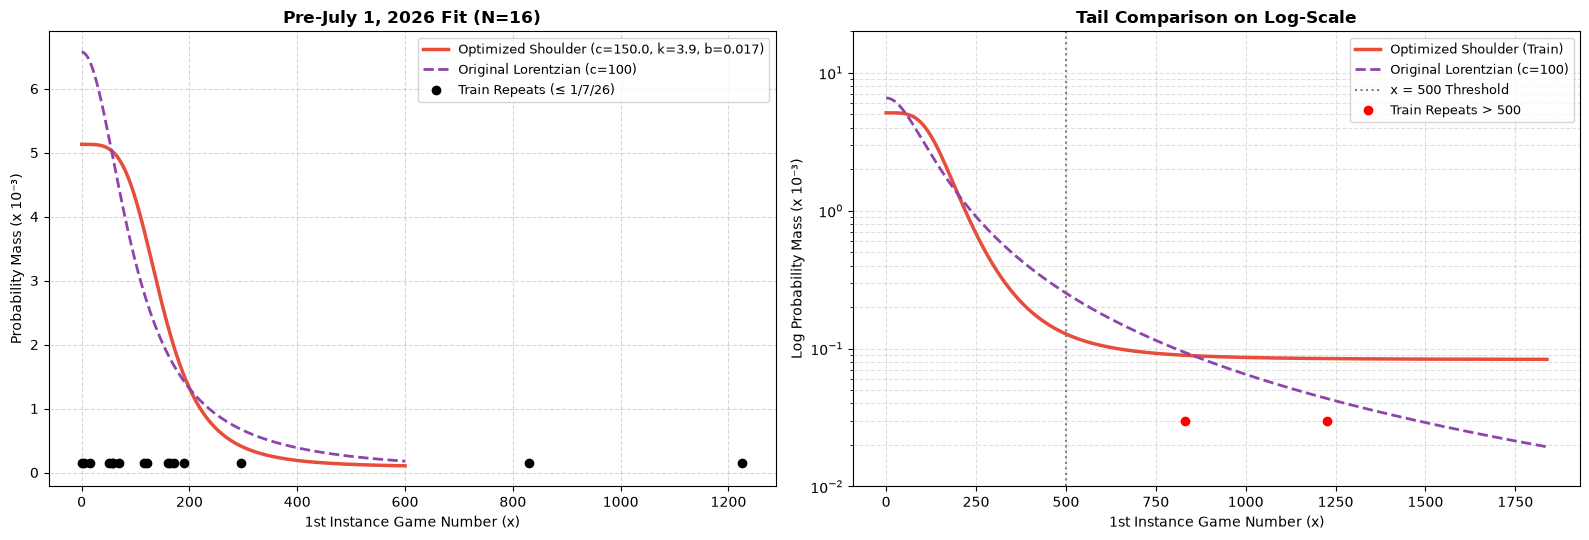

In [10]:
# ==============================================================================
# OPTIMIZATION & COMPARISON: SMOOTH SHOULDER-DROPOFF MODEL VS. ORIGINAL LORENTZIAN
# ==============================================================================

def shoulder_dropoff_pdf(x, c, k, b):
    w = (1.0 / (1.0 + (x / c) ** k)) + b
    return w / np.sum(w)

def fit_shoulder_model(origins_arr, horizon):
    """Optimizes c, k, b via Maximum Log-Likelihood for a given set of observed origins."""
    x_dom = np.arange(0, horizon + 1, dtype=float)
    
    def neg_ll(params):
        c, k, b = params
        if c <= 10 or k < 2.0 or k > 8.0 or b < 0.0 or b > 0.1:
            return 1e10
        prob = shoulder_dropoff_pdf(x_dom, c, k, b)
        return -np.sum(np.log(prob[origins_arr]))

    res = optimize.minimize(
        neg_ll,
        x0=[150.0, 4.0, 0.01],
        bounds=[(30.0, 400.0), (2.0, 7.0), (0.0, 0.05)],
        method='L-BFGS-B'
    )
    return res.x, -res.fun

# 1. Prepare Datasets
# Pre-July 1, 2026 Dataset (Training)
train_origins = observed_origins.astype(int)
horizon_train = int(df['game_num'].max())

# All Data Dataset (Full 24 Repeats up to Sep/Oct 2026)[cite: 1]
df_full_all = df_full.copy()
df_full_all['occurrence'] = df_full_all.groupby('solution').cumcount() + 1
r_full_all = df_full_all[df_full_all['occurrence'] == 1].set_index('solution')[['game_num', 'date']].join(
    df_full_all[df_full_all['occurrence'] == 2].set_index('solution')[['game_num', 'date']],
    lsuffix='_1st', rsuffix='_2nd', how='inner'
).reset_index()
all_origins = r_full_all['game_num_1st'].values.astype(int)
horizon_all = int(df_full_all['game_num'].max())

# 2. Run Optimizations
opt_train, ll_train = fit_shoulder_model(train_origins, horizon_train)
opt_all, ll_all = fit_shoulder_model(all_origins, horizon_all)

# Original Lorentzian Baseline (c = 100)
x_train_dom = np.arange(0, horizon_train + 1, dtype=float)
x_all_dom = np.arange(0, horizon_all + 1, dtype=float)

orig_pdf_train = 1.0 / (1.0 + (x_train_dom / 100.0) ** 2)
orig_pdf_train /= np.sum(orig_pdf_train)
ll_orig_train = np.sum(np.log(orig_pdf_train[train_origins]))

orig_pdf_all = 1.0 / (1.0 + (x_all_dom / 100.0) ** 2)
orig_pdf_all /= np.sum(orig_pdf_all)
ll_orig_all = np.sum(np.log(orig_pdf_all[all_origins]))

print("=" * 80)
print("OPTIMIZATION RESULTS: SHOULDER-DROPOFF MODEL VS. ORIGINAL LORENTZIAN")
print("=" * 80)
print(f"1. PRE-JULY 1, 2026 DATA (N = {len(train_origins)}):")
print(f"   * Original Lorentzian (c=100) Log-Likelihood : {ll_orig_train:.4f}")
print(f"   * Optimized Shoulder Model Log-Likelihood    : {ll_train:.4f} (Delta: {ll_train - ll_orig_train:+.4f})")
print(f"     -> Optimized Parameters: c = {opt_train[0]:.2f}, k = {opt_train[1]:.2f}, b = {opt_train[2]:.4f}")
print("-" * 80)
print(f"2. ALL DATA (UP TO LATEST REPEAT, N = {len(all_origins)}):")
print(f"   * Original Lorentzian (c=100) Log-Likelihood : {ll_orig_all:.4f}")
print(f"     -> Optimized Shoulder Model Log-Likelihood    : {ll_all:.4f} (Delta: {ll_all - ll_orig_all:+.4f})")
print(f"     -> Optimized Parameters: c = {opt_all[0]:.2f}, k = {opt_all[1]:.2f}, b = {opt_all[2]:.4f}")
print("=" * 80)

# 3. Plotting Comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Model curves
w_opt_train = shoulder_dropoff_pdf(x_train_dom, *opt_train)

# --- Left Panel: Pre-July 1 Fit vs Original Lorentzian ---
axes[0].plot(x_train_dom[:601], w_opt_train[:601] * 1000, color='#e74c3c', lw=2.5, 
             label=f'Optimized Shoulder (c={opt_train[0]:.1f}, k={opt_train[1]:.1f}, b={opt_train[2]:.3f})')
axes[0].plot(x_train_dom[:601], orig_pdf_train[:601] * 1000, color='#8e44ad', lw=2.0, linestyle='--', 
             label='Original Lorentzian (c=100)')
axes[0].plot(train_origins, [0.15]*len(train_origins), 'ko', markersize=6, label='Train Repeats (≤ 1/7/26)')
axes[0].set_title("Pre-July 1, 2026 Fit (N=16)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("1st Instance Game Number (x)")
axes[0].set_ylabel("Probability Mass (x 10⁻³)")
axes[0].legend(fontsize=9)
axes[0].grid(True, linestyle='--', alpha=0.5)

# --- Right Panel: Log-Scale Tail Comparison ---
axes[1].plot(x_train_dom, w_opt_train * 1000, color='#e74c3c', lw=2.5, label='Optimized Shoulder (Train)')
axes[1].plot(x_train_dom, orig_pdf_train * 1000, color='#8e44ad', lw=2.0, linestyle='--', label='Original Lorentzian (c=100)')
axes[1].set_yscale('log')
axes[1].axvline(500, color='gray', linestyle=':', label='x = 500 Threshold')
axes[1].plot(train_origins[train_origins > 500], [0.03]*np.sum(train_origins > 500), 'ro', markersize=6, label='Train Repeats > 500')
axes[1].set_title("Tail Comparison on Log-Scale", fontsize=12, fontweight='bold')
axes[1].set_xlabel("1st Instance Game Number (x)")
axes[1].set_ylabel("Log Probability Mass (x 10⁻³)")
axes[1].set_ylim(1e-2, 20)
axes[1].legend(fontsize=9)
axes[1].grid(True, which="both", linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()